# Basics of Kinematic Electron Diffraction — Aluminum

**CITEAM 2027 training module (draft) — Part B: Simulate**

This notebook builds electron diffraction from first principles — Bragg's law, the reciprocal
lattice, the Ewald sphere, excitation errors, and structure factors — for **fcc aluminum**,
then validates the result against the `diffsims` simulation engine and against a **real
selected-area diffraction pattern of Al** acquired at the University of Maryland.

The pedagogical structure follows, with permission and gratitude, the *Basics of Diffraction*
notebook by **Gerd Duscher and Sergei Kalinin** (MLSTEM 2026 workshop, University of Tennessee,
Knoxville — [github.com/gduscher/MLSTEM2026](https://github.com/gduscher/MLSTEM2026)),
reimplemented here on the **HyperSpy ecosystem** (`hyperspy`, `diffsims`, `ase`) used throughout
CITEAM. Theory notation matches the CITEAM lecture *Electron Diffraction Patterns from Al*.

Content:
1. The Al crystal in real space
2. Electron wavelength
3. Reciprocal lattice and Laue zones
4. The Ewald sphere: TEM vs. X-ray
5. Tilting the sample ≡ tilting the sphere
6. Excitation error $s_g$
7. Structure factors and allowed reflections
8. 3D Ewald sphere, ZOLZ and HOLZ
9. Validation with `diffsims`
10. Closing the loop: overlay on an experimental Al pattern
11. Data-management epilogue: from orphan TIF to self-describing dataset


In [1]:
import sys, importlib.metadata

def test_package(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return '-1'

for pkg in ['hyperspy', 'diffsims', 'ase', 'imagecodecs']:
    if test_package(pkg) == '-1':
        print(f'installing {pkg}')
        !{sys.executable} -m pip install {pkg} -q
print('done')

done


In [2]:
%matplotlib inline
# On Google Colab / JupyterLab with ipympl installed, '%matplotlib widget'
# gives interactive (rotatable) 3D figures. 'inline' guarantees static
# figures everywhere and keeps the executed notebook archivable.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import itertools
import scipy.constants as const
from scipy import ndimage

import ase
import ase.build
import hyperspy.api as hs
import diffsims

# Show version numbers for provenance / archiving.
__notebook_version__ = '2026.09.30-CITEAM-draft'
print('notebook version:', __notebook_version__)
for m in (np, matplotlib, ase, hs, diffsims):
    print(f'{m.__name__:12s}', m.__version__)

notebook version: 2026.09.30-CITEAM-draft
numpy        2.4.4
matplotlib   3.10.8
ase          3.29.0
hyperspy.api 2.4.0
diffsims     0.7.0


## 1. The Al crystal in real space

Aluminum is face-centered cubic (space group $Fm\bar{3}m$, no. 225) with lattice constant
$a = 4.0494$ Å and basis atoms at $(0,0,0)$, $(\tfrac12,\tfrac12,0)$, $(\tfrac12,0,\tfrac12)$,
$(0,\tfrac12,\tfrac12)$ — the same ICSD values used in the lecture. We build the
**conventional cubic cell** with `ase` (note `cubic=True`: the fcc primitive cell has only
one atom and would hide the extinction rules we want to derive).

In [3]:
atoms = ase.build.bulk('Al', 'fcc', a=4.0494, cubic=True)
print(atoms)
print('fractional positions:\n', atoms.get_scaled_positions())
print(f'unit-cell volume: {atoms.cell.volume:.2f} A^3')

Atoms(symbols='Al4', pbc=True, cell=[4.0494, 4.0494, 4.0494])
fractional positions:
 [[0.  0.  0. ]
 [0.  0.5 0.5]
 [0.5 0.  0.5]
 [0.5 0.5 0. ]]
unit-cell volume: 66.40 A^3


## 2. Electron wavelength

The relativistically corrected de Broglie wavelength for electrons accelerated through
a potential $V$:

$$\lambda = \frac{h}{\sqrt{2 m_e e V \left(1 + \dfrac{eV}{2 m_e c^2}\right)}}$$

We write it out explicitly (three lines of physics beat a black box) and cross-check
against `diffsims`.

In [4]:
def get_wavelength(acceleration_voltage_V):
    '''Relativistic electron wavelength in Angstrom.'''
    V = acceleration_voltage_V
    momentum = np.sqrt(2 * const.m_e * const.e * V * (1 + const.e * V / (2 * const.m_e * const.c**2)))
    return const.h / momentum * 1e10  # m -> Angstrom

acceleration_voltage_V = 200.0 * 1000.0  # V

wave_length_A = get_wavelength(acceleration_voltage_V)
print(f'The wavelength for {acceleration_voltage_V/1000:.1f} kV is: {wave_length_A*100:.5f} pm')

K0_magnitude = 1 / wave_length_A
print(f'The magnitude of the incident wavevector is {K0_magnitude*10:.2f} 1/nm')

# cross-check against the diffsims implementation (takes kV)
from diffsims.utils.sim_utils import get_electron_wavelength
assert np.isclose(wave_length_A, get_electron_wavelength(acceleration_voltage_V/1000), rtol=1e-6)
print('matches diffsims.utils.sim_utils.get_electron_wavelength')

The wavelength for 200.0 kV is: 2.50793 pm
The magnitude of the incident wavevector is 398.73 1/nm


matches diffsims.utils.sim_utils.get_electron_wavelength


## 3. Reciprocal lattice and Laue zones

The reciprocal cell follows from inverting the real cell matrix; `ase` provides it directly.
We then enumerate reciprocal-lattice points $\vec g = h\vec a^* + k\vec b^* + l\vec c^*$
and view them side-on (beam along $[001]$), which sorts them into **Laue zones**: the
zero-order zone (ZOLZ) in the plane through the origin, and first/second-order zones
(FOLZ, SOLZ) above it.

In [5]:
zone = [0, 0, 1]  # beam direction, parallel to z for simplicity

reciprocal_lattice = np.array(atoms.cell.reciprocal())  # = np.linalg.inv(atoms.cell).T
print('reciprocal lattice (1/A):\n', reciprocal_lattice.round(4))

zone_vector = np.dot(zone, reciprocal_lattice)
K0_unit_vector = zone_vector / np.linalg.norm(zone_vector)
K0_vector = K0_unit_vector * K0_magnitude
print('incident wavevector:', K0_vector.round(3), '1/A')

reciprocal lattice (1/A):
 [[0.247 0.    0.   ]
 [0.    0.247 0.   ]
 [0.    0.    0.247]]
incident wavevector: [ 0.     0.    39.873] 1/A


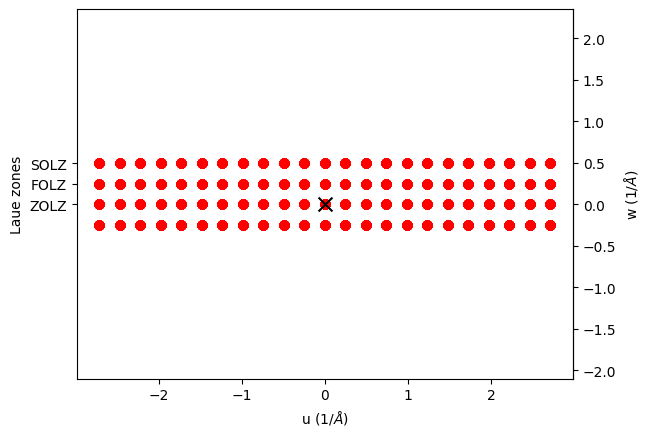

In [6]:
hkl_max = 11
indices_u_v = np.linspace(-hkl_max, hkl_max, 2*hkl_max + 1)
indices_w = np.linspace(-1, 2, 4)
hkl = np.array(list(itertools.product(indices_u_v, indices_u_v, indices_w)))

g = np.dot(hkl, reciprocal_lattice)  # all evaluated reciprocal-lattice points

fig, ax = plt.subplots()
ax.scatter(g[:, 0], g[:, 2], c='red', s=40)
ax.scatter(0, 0, c='black', s=100, marker='x')
ax.axis('equal')
ax.set_yticks(np.unique(g[:, 2])[1:4])
ax.set_yticklabels(['ZOLZ', 'FOLZ', 'SOLZ'])
secax = ax.secondary_yaxis('right')
secax.set_ylabel('w (1/$\\AA$)')
ax.set_xlabel('u (1/$\\AA$)')
ax.set_ylabel('Laue zones');

## 4. The Ewald sphere: TEM vs. X-ray

The Ewald sphere has radius $|\vec K_0| = 1/\lambda$ and passes through the origin of
reciprocal space. For 200 kV electrons the radius (~40 Å⁻¹) is enormous compared with
the reciprocal-lattice spacing (~0.25 Å⁻¹), so the sphere is nearly flat where it meets
the ZOLZ — which is why a single zone-axis pattern lights up so many reflections at once.
Compare Cu-K$\alpha$ X-rays ($\lambda = 1.5418$ Å), whose sphere is tightly curved.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


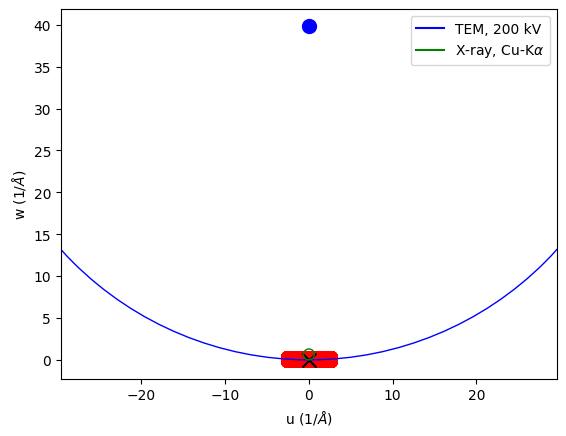

In [7]:
fig, ax = plt.subplots()
ax.scatter(g[:, 0], g[:, 2], c='red', s=40)
ax.scatter(0, K0_magnitude, c='blue', s=100)
ax.scatter(0, 0, c='black', s=100, marker='x')
ax.add_artist(plt.Circle((0, K0_magnitude), K0_magnitude, color='b', fill=False))
ax.add_artist(plt.Circle((0, 1/1.5418), 1/1.5418, color='g', fill=False))
ax.axis('equal')
ax.set_xlabel('u (1/$\\AA$)')
ax.set_ylabel('w (1/$\\AA$)')
ax.plot([], [], color='b', label='TEM, 200 kV')
ax.plot([], [], color='g', label=r'X-ray, Cu-K$\alpha$')
ax.legend()
ax.set_xlim(-15, 15);

## 5. Tilting the sample ≡ tilting the sphere

Experimentally we tilt the specimen; mathematically it is identical (and easier) to tilt
the Ewald sphere the opposite way and keep the crystal fixed. Both views below show the
same physics.

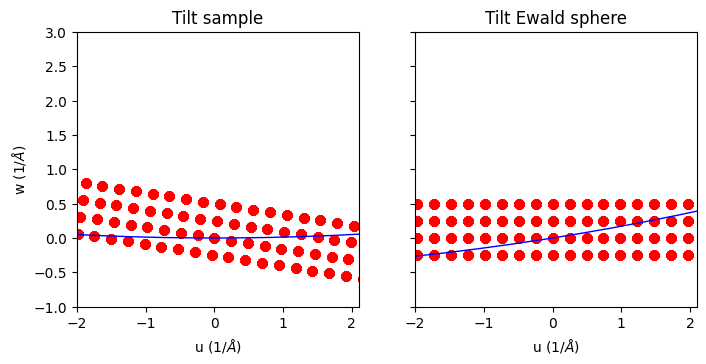

In [8]:
# ---- Input ----
tilt_angle = 9.0  # degrees
# ---------------

t = np.radians(tilt_angle)
R2 = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
K0_tilt = np.dot([0, K0_magnitude], R2)
g_tilt = np.dot(g[:, [0, 2]], R2)

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
ax1.scatter(g_tilt[:, 0], g_tilt[:, 1], c='red', s=40)
ax1.scatter(0, K0_magnitude, c='blue', s=80)
ax1.add_artist(plt.Circle((0, K0_magnitude), K0_magnitude, color='b', fill=False))
ax1.set_aspect('equal'); ax1.set_title('Tilt sample')
ax1.set_xlabel('u (1/$\\AA$)'); ax1.set_ylabel('w (1/$\\AA$)')

ax2.scatter(g[:, 0], g[:, 2], c='red', s=40)
ax2.scatter(-K0_tilt[0], K0_tilt[1], c='blue', s=80)
ax2.add_artist(plt.Circle((-K0_tilt[0], K0_tilt[1]), K0_magnitude, color='b', fill=False))
ax2.set_aspect('equal'); ax2.set_title('Tilt Ewald sphere')
ax2.set_xlabel('u (1/$\\AA$)')
ax1.set_xlim(-2, 2.1); ax1.set_ylim(-1, 3);

## 6. Excitation error $s_g$

A reciprocal-lattice point rarely sits *exactly* on the sphere. Its distance from the
sphere along the beam direction is the **excitation error** $\vec s_g$, and the diffracted
wavevector is $\vec K_g = \vec K_0 + \vec g + \vec s_g$. Intensity falls off rapidly with
$|s_g|$, which is what makes zone-axis patterns sharp. The zoomed construction below shows
$\vec g_{ZOLZ}$, $\vec s_g$ and $\vec K_g$ around one reflection.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


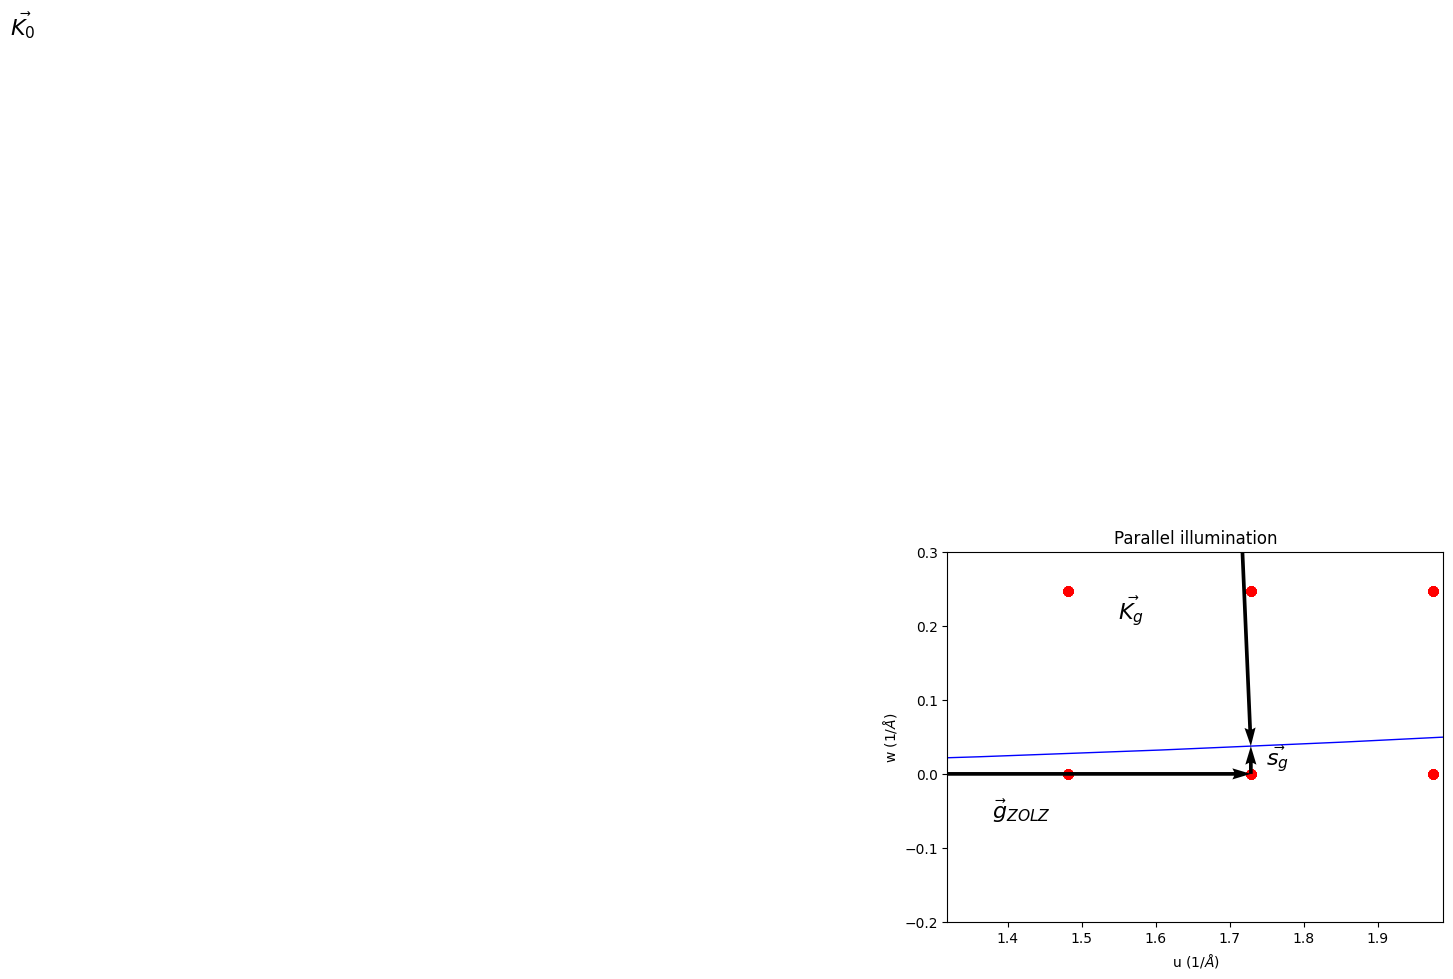

In [9]:
# pick the in-plane reflection closest to u = 1.75 1/A in the ZOLZ for the zoom
zolz = g[np.isclose(g[:, 2], 0) & (g[:, 1] == 0) & (g[:, 0] > 0)]
g_show = zolz[np.argmin(np.abs(zolz[:, 0] - 1.75))]
s_g = K0_magnitude - np.sqrt(K0_magnitude**2 - g_show[0]**2)  # sphere sag at u = g

fig, ax = plt.subplots()
ax.scatter(g[:, 0], g[:, 2], c='red', s=40)
ax.scatter(0, K0_magnitude, c='green', s=40)
ax.add_artist(plt.Circle((0, K0_magnitude), K0_magnitude, color='b', fill=False))
ax.quiver([0, 0, 0, g_show[0]], [K0_magnitude, K0_magnitude, 0, 0],
          [0, g_show[0], g_show[0], 0], [-K0_magnitude, -K0_magnitude + s_g, 0, s_g],
          units='xy', scale=1, width=.005)
ax.text(g_show[0] + .02, s_g/3, r'$\vec{s_g}$', size=16)
ax.text(g_show[0] - .35, -.06, r'$\vec{g}_{ZOLZ}$', size=16)
ax.text(g_show[0] - .18, .21, r'$\vec{K_g}$', size=16)
ax.text(.05, 1., r'$\vec{K_0}$', size=16)
ax.set_title('Parallel illumination')
ax.axis('equal')
ax.set_xlabel('u (1/$\\AA$)'); ax.set_ylabel('w (1/$\\AA$)')
ax.set_xlim(g_show[0] - .4, g_show[0] + .25); ax.set_ylim(-.2, .3);

## 7. Structure factors and allowed reflections

The intensity of reflection $\vec g$ is governed by the **structure factor**

$$F_g = \sum_{i \,\in\, u.c.} f_i(|\vec g|)\; e^{-2\pi i\, \vec g \cdot \vec r_i}$$

with $f_i$ the atomic form factor. Instead of pyTEMlib's Kirkland tables we take the
**Lobato & Van Dyck (2014) parameterization shipped with `diffsims`** and evaluate it
explicitly:

$$f(g) = \sum_{j=1}^{5} a_j \frac{2 + b_j g^2}{\left(1 + b_j g^2\right)^2}$$

For fcc, the four-atom basis makes $F_g = 4 f_{Al}$ when $h,k,l$ are **all even or all odd**,
and $F_g = 0$ otherwise — exactly the $F_{hkl}$ table in the lecture slides.

The form factor at $g=0$ also gives the **mean inner potential** $U_0$, which slightly
lengthens the wavevector inside the crystal (refraction).

In [10]:
from diffsims.utils.lobato_scattering_params import ATOMIC_SCATTERING_PARAMS_LOBATO

def form_factor(symbol, g_length_invA):
    '''Electron atomic form factor f(g) in Angstrom, Lobato & Van Dyck (2014).'''
    a_b = np.array(ATOMIC_SCATTERING_PARAMS_LOBATO[symbol])  # shape (5, 2)
    a, b = a_b[:, 0], a_b[:, 1]
    g2 = np.asarray(g_length_invA, float)**2
    return np.sum(a * (2 + b * g2[..., None]) / (1 + b * g2[..., None])**2, axis=-1)

# mean inner potential from f(0)
scattering_factor_to_volts = (const.h * 1e10)**2 / (2 * np.pi * const.m_e * const.e) / atoms.cell.volume
U_0 = sum(form_factor(at.symbol, 0.0) for at in atoms) * scattering_factor_to_volts
print(f'The mean inner potential is {U_0:.1f} V')

# wavevector inside the crystal (refraction-corrected)
K0_magnitude = np.sqrt(1 / wave_length_A**2 + U_0)  # 1/A
print(f'|K0| in vacuum : {1/wave_length_A:.4f} 1/A')
print(f'|K0| in crystal: {K0_magnitude:.4f} 1/A')

The mean inner potential is 17.0 V
|K0| in vacuum : 39.8735 1/A
|K0| in crystal: 40.0859 1/A


In [11]:
# --------------- INPUT ------------------------
zone_hkl = np.array([1, 1, 0])   # zone axis with both ZOLZ and HOLZ character
hkl_max = 25                     # maximum Miller index evaluated
Sg_max = 0.03                    # 1/A, maximum allowed excitation error
# ----------------------------------------------

cent = np.dot(zone_hkl, reciprocal_lattice)
cent = cent / np.linalg.norm(cent) * K0_magnitude  # center of the Ewald sphere

h = np.linspace(-hkl_max, hkl_max, 2*hkl_max + 1)
hkl = np.array(list(itertools.product(h, h, h)))
g = np.dot(hkl, reciprocal_lattice)

# excitation errors for ALL points (Zuo & Spence, Adv. TEM 2017, eq. 3.14)
S = (K0_magnitude**2 - np.linalg.norm(g - cent, axis=1)**2) / (2 * K0_magnitude)

reflections = np.abs(S) < Sg_max
Sg, g_hkl, hkl = S[reflections], g[reflections], hkl[reflections]
print(f'Of the {len(g)} tested reciprocal-lattice points, '
      f'{len(g_hkl)} lie within {Sg_max} 1/A of the Ewald sphere')

# structure factors (explicit loop — the pedagogical heart of this notebook)
g_norms = np.linalg.norm(g_hkl, axis=1)
F = np.zeros(len(g_hkl), dtype=complex)
for at in atoms:
    F += form_factor(at.symbol, g_norms) * np.exp(-2j * np.pi * (g_hkl @ at.position))

allowed = np.abs(F) > 1e-6
print(f'Of those, {allowed.sum()} are allowed by the fcc structure factor')

Sg_allowed = Sg[allowed]
hkl_allowed = hkl[allowed].astype(int)
g_allowed = g_hkl[allowed]
F_allowed = F[allowed]
intensities = np.abs(F_allowed)**2
g_forbidden = g_hkl[~allowed]

# Laue zones (cubic shortcut, as in the original notebook)
Laue_Zone = np.floor(np.abs(hkl_allowed @ zone_hkl))
ZOLZ = Laue_Zone == 0
HOLZ = Laue_Zone > 1
print(f'ZOLZ: {ZOLZ.sum()} reflections, HOLZ: {HOLZ.sum()} reflections')

Of the 132651 tested reciprocal-lattice points, 803 lie within 0.03 1/A of the Ewald sphere
Of those, 195 are allowed by the fcc structure factor
ZOLZ: 43 reflections, HOLZ: 152 reflections


In [12]:
# reproduce the F_hkl table from the CITEAM lecture slides
print(' hkl   d_hkl (nm)   |F_hkl|')
print('-----------------------------')
a0 = 4.0494
for tag, (hh, kk, ll) in [('100', (1,0,0)), ('200', (2,0,0)), ('110', (1,1,0)), ('220', (2,2,0)), ('111', (1,1,1))]:
    d = a0 / np.sqrt(hh**2 + kk**2 + ll**2)
    gv = np.dot([hh, kk, ll], reciprocal_lattice)
    Fv = sum(form_factor(at.symbol, np.linalg.norm(gv)) * np.exp(-2j*np.pi*(gv @ at.position)) for at in atoms)
    label = f'4 f_Al = {abs(Fv):.2f} A' if abs(Fv) > 1e-6 else '0  (forbidden)'
    print(f' {tag}   {d/10:.4f}       {label}')

 hkl   d_hkl (nm)   |F_hkl|
-----------------------------
 100   0.4049       0  (forbidden)
 200   0.2025       4 f_Al = 7.06 A
 110   0.2863       0  (forbidden)
 220   0.1432       4 f_Al = 4.46 A
 111   0.2338       4 f_Al = 8.47 A


Compare with the lecture: $d_{100}=0.4049$ nm with $F=0$, $d_{200}=0.2025$ nm with
$F = 4f_{Al}$, $d_{110}=0.286$ nm with $F=0$, $d_{220}=0.143$ nm with $F = 4f_{Al}$. ✔

## 8. 3D Ewald sphere, ZOLZ and HOLZ

Now the full 3D construction for the $[110]$ zone: allowed reflections near the sphere,
colored by Laue zone, then rotated so the zone axis is vertical and **projected onto the
detector plane** — which is precisely what the microscope records.

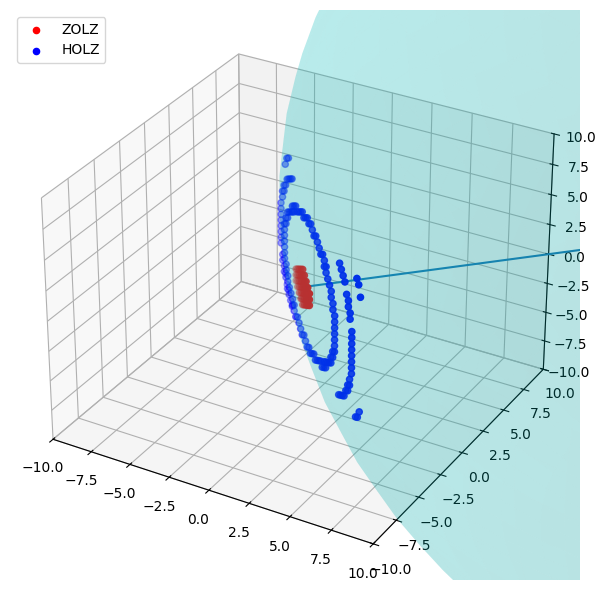

In [13]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
u, v = np.mgrid[0:2*np.pi:80j, 0:np.pi:40j]
ax.plot_surface(np.cos(u)*np.sin(v)*K0_magnitude + cent[0],
                np.sin(u)*np.sin(v)*K0_magnitude + cent[1],
                np.cos(v)*K0_magnitude + cent[2],
                rstride=1, cstride=1, color='c', alpha=0.15, linewidth=0)
ax.scatter(g_allowed[ZOLZ, 0], g_allowed[ZOLZ, 1], g_allowed[ZOLZ, 2], c='red', label='ZOLZ')
ax.scatter(g_allowed[HOLZ, 0], g_allowed[HOLZ, 1], g_allowed[HOLZ, 2], c='blue', label='HOLZ')
ax.scatter(*cent, c='green'); ax.plot((cent[0], 0), (cent[1], 0), (cent[2], 0))
ax.set_xlim(-10, 10); ax.set_ylim(-10, 10); ax.set_zlim(-10, 10)
ax.legend(); plt.tight_layout();

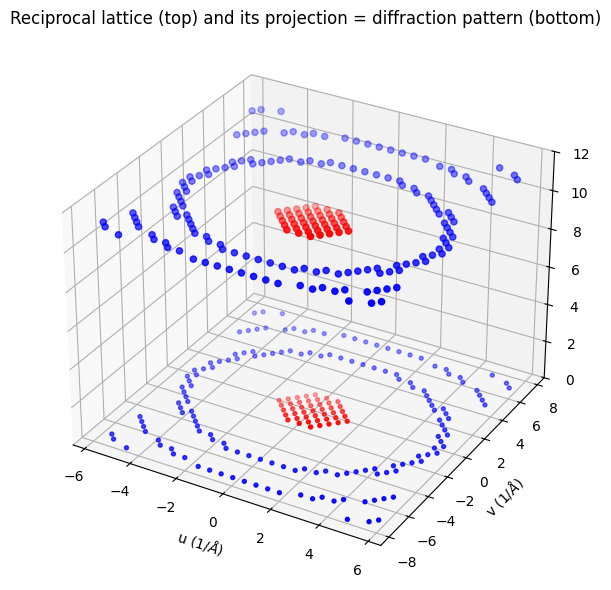

In [14]:
def get_rotation_matrix(zone_vec):
    '''Rotation that brings zone_vec parallel to the z axis.'''
    r = np.linalg.norm(zone_vec)
    theta = np.arccos(zone_vec[2] / r)
    if zone_vec[0] < 0:
        theta = -theta
    phi = np.pi/2 if zone_vec[0] == 0 else np.arctan(zone_vec[1] / zone_vec[0])
    c, s = np.cos(phi), np.sin(phi)
    rotz = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
    c, s = np.cos(theta), np.sin(theta)
    roty = np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
    return rotz @ roty

rotation_matrix = get_rotation_matrix(np.dot(zone_hkl, reciprocal_lattice))
g_rot = g_allowed @ rotation_matrix

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(g_rot[ZOLZ, 0], g_rot[ZOLZ, 1], g_rot[ZOLZ, 2] + 10, c='red')
ax.scatter(g_rot[HOLZ, 0], g_rot[HOLZ, 1], g_rot[HOLZ, 2] + 10, c='blue')
ax.scatter(g_rot[ZOLZ, 0], g_rot[ZOLZ, 1], 0, c='red', s=8)
ax.scatter(g_rot[HOLZ, 0], g_rot[HOLZ, 1], 0, c='blue', s=8)
ax.set_zlim(0, 12)
ax.set_xlabel('u (1/$\\AA$)'); ax.set_ylabel('v (1/$\\AA$)')
ax.set_title('Reciprocal lattice (top) and its projection = diffraction pattern (bottom)')
plt.tight_layout();

## 9. Validation with `diffsims`

Everything above was explicit numpy. The HyperSpy ecosystem packages the same kinematic
physics in `diffsims.generators.simulation_generator.SimulationGenerator`. We simulate the
three zone axes of the **UMD experimental patterns** — $[001]$, $[\bar 1 11]$, $[11\bar 2]$ —
and index the spots ourselves from geometry ($hkl_i = \vec g \cdot \vec a_i$), which keeps
the labels in the conventional-cell setting used in the lecture.

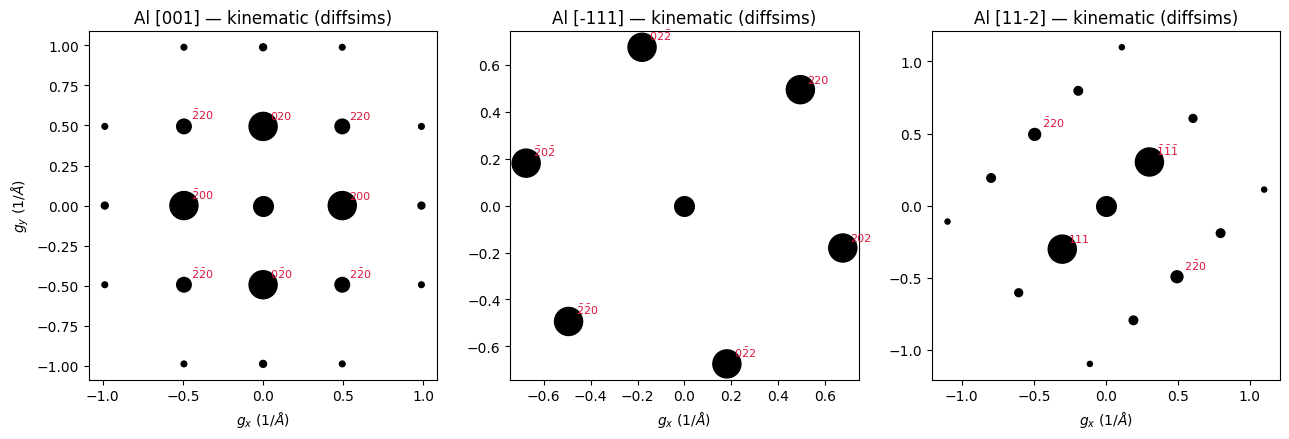

In [15]:
import diffpy.structure
from orix.crystal_map import Phase
from orix.quaternion import Rotation
from orix.vector import Vector3d
from diffsims.generators.simulation_generator import SimulationGenerator

al_diffpy = diffpy.structure.Structure(
    atoms=[diffpy.structure.Atom('Al', p) for p in
           [[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]]],
    lattice=diffpy.structure.Lattice(4.0494, 4.0494, 4.0494, 90, 90, 90))
phase = Phase(name='Al', space_group=225, structure=al_diffpy)
gen = SimulationGenerator(accelerating_voltage=200, scattering_params='lobato')

zones = {'[001]': [0, 0, 1], '[-111]': [-1, 1, 1], '[11-2]': [1, 1, -2]}
real_cell = np.array(atoms.cell)   # rows = a, b, c

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
sims = {}
for ax, (label, zv) in zip(axes, zones.items()):
    rot, _ = Rotation.from_align_vectors(Vector3d.zvector(),
                                         Vector3d(np.array(zv, float)), return_rmsd=True)
    sim = gen.calculate_diffraction2d(phase, rotation=rot,
                                      reciprocal_radius=1.3, max_excitation_error=0.02)
    co = sim.coordinates
    g3, I = np.array(co.data), np.array(co.intensity)
    keep = (np.linalg.norm(g3, axis=1) > 1e-6) & (I > 1e-3 * I.max())
    g3, I = g3[keep], I[keep]                         # drop direct beam & F=0 reflections
    # conventional hkl from geometry: hkl = g (cartesian, crystal frame) . a_i
    g_crys = (~rot * Vector3d(g3)).data               # rotate back to crystal frame
    hkl_lab = np.rint(g_crys @ real_cell.T).astype(int)
    xy = g3[:, :2]                                    # detector-plane components
    sims[label] = (xy, I, hkl_lab)
    ax.scatter(xy[:, 0], xy[:, 1], s=8 + 400 * I / I.max(), c='k')
    ax.scatter(0, 0, s=200, c='k')
    for (x, y), hklv, Iv in zip(xy[:, :2], hkl_lab, I):
        if np.linalg.norm([x, y]) < 0.75 and Iv > 0.02 * I.max():
            ax.annotate(''.join(f'{v}' if v >= 0 else f'$\\bar{{{-v}}}$' for v in hklv),
                        (x, y), textcoords='offset points', xytext=(5, 5), fontsize=8, color='crimson')
    ax.set_aspect('equal'); ax.set_title(f'Al {label} — kinematic (diffsims)')
    ax.set_xlabel('$g_x$ (1/$\\AA$)')
axes[0].set_ylabel('$g_y$ (1/$\\AA$)')
plt.tight_layout();

All three match the labeled patterns in the lecture slides: the square $\{200\}/\{020\}$
net in $[001]$, the hexagonal $\{220\}$ net in $[\bar 111]$, and the rectangular
$\{111\}/\{2\bar 20\}$ net in $[11\bar 2]$.

## 10. Closing the loop: overlay on the experimental pattern

Now the step the MLSTEM notebook stops short of: put the simulation **on top of a real
measurement**. We load the UMD Al pattern (area 1, $[001]$ zone) with HyperSpy, calibrate
it from its scale bar, and overlay the simulated reflections.

Note what `axes_manager` reports on loading: scale 1.0, units undefined. The TIF export
kept the pixels and threw away the calibration — we must recover it by measuring the
burned-in scale bar. Section 11 shows how to stop this happening to your own data.

In [16]:
import os
data_file = 'data/Al_No_3_area_1_DP_no_labels.tif'

if not os.path.exists(data_file):
    print(f'{data_file} not found - place the CITEAM data folder next to this notebook.')
else:
    s = hs.load(data_file)
    print(s)
    print('signal axes units:', [ax.units for ax in s.axes_manager.signal_axes])
    print('signal axes scale:', [ax.scale for ax in s.axes_manager.signal_axes])
    om = s.original_metadata.as_dictionary()
    def describe(d, indent=0):
        for k, v in d.items():
            if isinstance(v, dict):
                print(' ' * indent + f'{k}:'); describe(v, indent + 2)
            else:
                txt = repr(v)
                print(' ' * indent + f'{k}: ' + (txt if len(txt) < 60 else f'<{len(txt)} chars - binary/palette blob, no acquisition info>'))
    print('original_metadata tree:')
    describe(om)
    print('\nNo voltage, camera length, or calibration anywhere above -')
    print('the TIF export kept display baggage and lost the physics.')

<Signal2D, title: , dimensions: (|2004, 1336)>
signal axes units: [<undefined>, <undefined>]
signal axes scale: [1.0, 1.0]
original_metadata tree:
NewSubfileType: <FILETYPE.UNDEFINED: 0>
ImageWidth: 2004
ImageLength: 1336
BitsPerSample: 8
Compression: <COMPRESSION.LZW: 5>
PhotometricInterpretation: <PHOTOMETRIC.PALETTE: 3>
ImageDescription: ''
StripOffsets: <1370 chars - binary/palette blob, no acquisition info>
Orientation: <ORIENTATION.TOPLEFT: 1>
SamplesPerPixel: 1
RowsPerStrip: 8
StripByteCounts: <1005 chars - binary/palette blob, no acquisition info>
XResolution: (72, 1)
YResolution: (72, 1)
PlanarConfiguration: <PLANARCONFIG.CONTIG: 1>
ResolutionUnit: <RESUNIT.INCH: 2>
ColorMap: <6089 chars - binary/palette blob, no acquisition info>
SampleFormat: <SAMPLEFORMAT.UINT: 1>
65006: -0.0
65007: -0.0
65009: 1.0
65010: 1.0
65015: 1
65016: 1
65024: 0.0
65025: 1.0
65026: 1
JEOL_Header: <33265 chars - binary/palette blob, no acquisition info>

No voltage, camera length, or calibration anywh

calibration: 12.755 x 10^-3 1/nm per pixel
predicted {200} ring radius: 387 px (compare with the spots you measure - within a few percent)


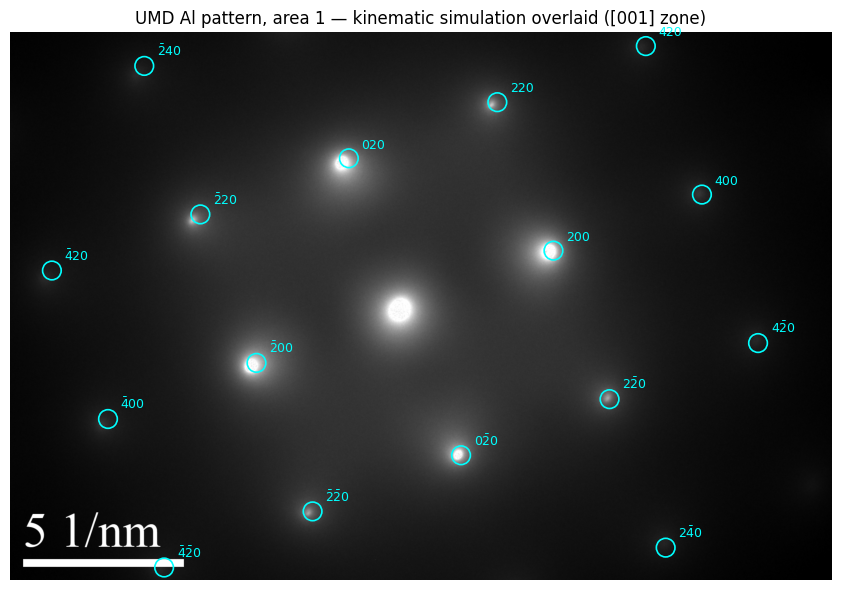

In [17]:
if os.path.exists(data_file):
    # ------------------------- INPUT -------------------------
    scale_bar_invnm = 5.0      # value printed on the burned-in scale bar (1/nm)
    scale_bar_px = 392         # measured length of the bar in pixels
    center_px = (963, 669)     # (x, y) of the transmitted beam, in pixels
    rotation_deg = 20.7        # in-plane rotation between simulation and experiment
    # ---------------------------------------------------------

    calib = scale_bar_invnm / scale_bar_px       # 1/nm per pixel
    print(f'calibration: {calib*1000:.3f} x 10^-3 1/nm per pixel')

    img = np.asarray(s.data, float)
    xy, I, hkl_lab = sims['[001]']
    th = np.radians(rotation_deg)
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    xy_rot = xy @ R.T
    px = center_px[0] + xy_rot[:, 0] * 10 / calib      # 1/A -> 1/nm -> px
    py = center_px[1] - xy_rot[:, 1] * 10 / calib      # image y axis points down

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(img, cmap='gray', vmax=np.percentile(img, 99.95))
    inside = (px > 0) & (px < img.shape[1]) & (py > 0) & (py < img.shape[0])
    ax.scatter(px[inside], py[inside], s=180, facecolors='none', edgecolors='cyan', linewidths=1.2)
    for x, y, hklv in zip(px[inside], py[inside], hkl_lab[inside]):
        ax.annotate(''.join(f'{v}' if v >= 0 else f'$\\bar{{{-v}}}$' for v in hklv),
                    (x, y), textcoords='offset points', xytext=(9, 7), fontsize=9, color='cyan')
    ax.set_title('UMD Al pattern, area 1 — kinematic simulation overlaid ([001] zone)')
    ax.axis('off')
    plt.tight_layout()

    # quantitative check: predicted vs measured radius of the {200} ring
    r200_pred = np.linalg.norm(np.dot([2, 0, 0], reciprocal_lattice)) * 10 / calib
    print(f'predicted {{200}} ring radius: {r200_pred:.0f} px '
          '(compare with the spots you measure - within a few percent)')

**Exercise (Part C of the module):** repeat the overlay for `area_2` and the problem-set
pattern. Which zone axes are they? You will need to change `zone`, re-measure the scale bar
and center, and adjust `rotation_deg` until the circles land on the spots — exactly the
manual index-by-distances-and-angles workflow from the lecture, now automated.

## 11. Data-management epilogue: from orphan TIF to self-describing dataset

The TIF carried no calibration and no acquisition metadata. Having recovered the
calibration by hand, we now **attach it to the signal along with provenance** and save in
HyperSpy's native format, so the next person (including future-you) never has to measure
a scale bar again.

In [18]:
if os.path.exists(data_file):
    for ax, name in zip(s.axes_manager.signal_axes, ('kx', 'ky')):
        ax.name = name
        ax.units = '1/nm'
        ax.scale = calib
    s.axes_manager.signal_axes[0].offset = -center_px[0] * calib
    s.axes_manager.signal_axes[1].offset = -center_px[1] * calib

    s.metadata.set_item('General.title', 'SAD pattern, polycrystalline Al, area 1, [001] zone')
    s.metadata.set_item('Acquisition_instrument.TEM.beam_energy', 200.0)  # keV - confirm from lab records
    s.metadata.set_item('Sample.description', 'Polycrystalline Al film, UMD teaching sample No. 3')
    s.metadata.set_item('General.notes',
        'Calibration recovered from burned-in scale bar (5 1/nm = 392 px); '
        'original acquisition metadata lost on TIF export. '
        'Processed with CITEAM 2027 diffraction notebook v' + __notebook_version__)

    s.save('Al_area1_calibrated.hspy', overwrite=True)
    s2 = hs.load('Al_area1_calibrated.hspy')
    print(s2.axes_manager)
    print(s2.metadata)

<Axes manager, axes: (|2004, 1336)>
            Name |   size |  index |  offset |   scale |  units 
================ | ====== | ====== | ======= | ======= | ====== 
---------------- | ------ | ------ | ------- | ------- | ------ 
              kx |   2004 |      0 |     -12 |   0.013 |   1/nm 
              ky |   1336 |      0 |    -8.5 |   0.013 |   1/nm 
├── Acquisition_instrument
│   └── TEM
│       └── beam_energy = np.float64(200.0)
├── General
│   ├── FileIO
│   │   ├── 0
│   │   │   ├── hyperspy_version = 2.4.0
│   │   │   ├── io_plugin = rsciio.tiff
│   │   │   ├── operation = load
│   │   │   └── timestamp = 2026-09-30T19:07:21.547993+00:00
│   │   ├── 1
│   │   │   ├── hyperspy_version = 2.4.0
│   │   │   ├── io_plugin = rsciio.hspy
│   │   │   ├── operation = save
│   │   │   └── timestamp = 2026-09-30T19:07:22.405449+00:00
│   │   └── 2
│   │       ├── hyperspy_version = 2.4.0
│   │       ├── io_plugin = rsciio.hspy
│   │       ├── operation = load
│   │       └── timesta

The `.hspy` file now travels with its calibration, its provenance, and the notebook
version that produced it — the difference between an orphan image and a FAIR dataset.
The natural next step is a DOI-minted deposit (Zenodo via GitHub release, or the Materials
Data Facility) of the notebook together with the calibrated data.

---
### Attribution and references

- Pedagogical structure adapted from G. Duscher & S. Kalinin, *Basics of Diffraction*,
  MLSTEM 2026, University of Tennessee, Knoxville —
  [github.com/gduscher/MLSTEM2026](https://github.com/gduscher/MLSTEM2026).
- Theory notation follows the CITEAM lecture *Electron Diffraction Patterns from Al*
  (University of Maryland); experimental patterns courtesy of the CITEAM team.
- Form factors: I. Lobato & D. Van Dyck, *Acta Cryst.* A70 (2014) 636, as shipped with
  `diffsims`.
- Excitation-error formalism: J. M. Zuo & J. C. H. Spence, *Advanced Transmission Electron
  Microscopy*, Springer (2017), eq. 3.14.
- Software: HyperSpy, diffsims, orix, ASE — please cite their respective papers when
  publishing results.